# Pilot Study: Sizing the Noise-Sweep Degradation-Rate Comparison

Companion to `pilot_noise_power_analysis.ipynb` (which tests, at each SNR level
separately, whether methods differ) -- this notebook asks a different question:
**do methods degrade at different *rates* as noise increases?** That's a
method x noise-slope interaction test, not a level-by-level categorical
comparison, and it needs a different (though almost entirely reused) analysis.

**No new simulation or solving needed** -- this runs entirely on
`pilot_noise_outcomes.tsv` and `pilot_noise_variance_components.json`, both
already produced by `pilot_noise_power_analysis.ipynb`.

## Design

1. **Normalize**: express each method's outcome at each SNR level as *decline
   from that method's own SNR=20 baseline* (mean over repetitions, per
   region) -- isolates degradation from absolute performance, so the
   cross-method comparison isn't confounded by one method just being better
   overall. Sign-flipped so "positive = worse" is consistent across all four
   outcomes (loc-error is higher-is-worse; AP/correlation are higher-is-better).

2. **Reduce to one sufficient statistic per (region, method) cell**: a
   *weighted* least-squares slope of decline vs. `log(SNR)` across the 4
   non-reference levels (`[10, 5, 2, 1]` -- SNR=20 is used only to build the
   baseline, not refit as a regression point, to avoid double-dipping the
   same data). Weights are the *known* inverse noise variance at each level
   (`sigma2_rep + sigma2_resid`, already fit per-SNR-level by the companion
   notebook) plus the baseline's own sampling variance (`(sigma2_rep_20 +
   sigma2_resid_20) / R_pilot`) -- this accounts for substantial
   heteroscedasticity already visible in the existing fits (`sigma2_resid`
   for localization error ranges from ~92 at SNR=20 to ~780 at SNR=1, an
   ~8.5x spread), which plain unweighted OLS would ignore.

3. **What needs a fresh (small) fit vs. what's reused**: the per-level
   `sigma2_rep`/`sigma2_resid` are reused as-is (no refitting). What's new:
   the per-method mean slope (`beta_m`) and the region x method interaction
   variance *on the slope* (`sigma2_slope_interaction`, the analog of
   `sigma2_method_region` in the categorical model, now measured on the
   slope scale) -- estimated via method-of-moments: the observed
   between-region variance of the fitted slopes, minus the analytically-known
   slope-estimation-noise variance (`sigma2_slope_est`, a closed-form
   function of the design: SNR spacing, per-level noise, and `R` reps/level),
   floored at 0.

4. **The power test reuses `simulate_splitplot_power` completely
   unchanged.** Once each `(region, method)` cell is collapsed to a single
   slope value, "do slopes differ by method" is exactly the existing
   split-plot F-test (method main effect, using the region x method
   interaction as its error term) -- called with `r=1` (no further
   sub-replication once a cell is one slope value), `sigma2_group`/
   `sigma2_rep` set to 0 (they algebraically cancel in this test either
   way), and `sigma2_resid` set to the analytically-derived
   `sigma2_slope_est(R)` instead of a directly-fit residual. No new code
   needed in `mindmap.core.power`.

**Grid**: `k` = candidate region counts (same as every other pilot), `R` =
candcandidate repetitions *per SNR level* -- this is the one number that
actually changes shape here, since `R` no longer feeds power directly, it
feeds it through the slope-estimation-noise formula's `1/(R * Sxx)` term.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

import mindmap as mm

OUTCOMES = ["localization_error_hrp", "ap_hrp", "ap_pp", "correlation_auc"]
HIGHER_IS_BETTER = {"localization_error_hrp": False, "ap_hrp": True, "ap_pp": True, "correlation_auc": True}
METHODS = ["wcset", "cset", "mce", "sloreta", "dspm", "mne"]
M = len(METHODS)
REFERENCE_SNR = 20.0
NOISE_SNRS = [10.0, 5.0, 2.0, 1.0]
R_PILOT = 4   # repetitions per (region, method, snr) actually collected

df = pd.read_csv("pilot_noise_outcomes.tsv", sep="\t")
vc = json.load(open("pilot_noise_variance_components.json"))

print(f"{len(df)} rows, {df['region'].nunique()} regions, {df['method'].nunique()} methods, "
      f"snr levels {sorted(df['snr'].unique())}")

3120 rows, 26 regions, 6 methods, snr levels [np.float64(1.0), np.float64(2.0), np.float64(5.0), np.float64(10.0), np.float64(20.0)]


## Per-level noise variance (reused, not refit)

`V_s = sigma2_rep + sigma2_resid` at each SNR level, from the companion
notebook's existing per-level fits -- pooled across region and method
already (the original model's own homoscedasticity simplification), so one
number per `(snr, outcome)` is all that's needed.

In [2]:
V = {snr: {o: vc[str(int(snr))][o]["sigma2_rep"] + vc[str(int(snr))][o]["sigma2_resid"] for o in OUTCOMES}
     for snr in [REFERENCE_SNR] + NOISE_SNRS}

pd.DataFrame(V).T

,localization_error_hrp,ap_hrp,ap_pp,correlation_auc
20.0,92.297455,0.000820,0.000057,0.000078
10.0,335.254135,0.001068,0.000195,0.000082
5.0,552.344291,0.001130,0.000210,0.000117
2.0,555.338668,0.002423,0.000449,0.000112
1.0,781.274646,0.001390,0.000523,0.000156


## Per-(region, method) weighted slope of decline vs. log(SNR)

For each outcome: build the SNR=20 baseline (mean over repetitions, per
region x method), compute sign-flipped decline at each of the 4 non-reference
levels, then fit a weighted least-squares slope per `(region, method)` cell.
Weights are `R_pilot / V_s'` where `V_s' = V_s + baseline_variance` (baseline
variance = `V_20 / R_pilot`, since the baseline is itself a mean over
`R_pilot` repetitions).

In [3]:
def sigma2_slope_est(R, outcome):
    """Closed-form slope-estimation-noise variance for R repetitions/level (design-only, no region/method dependence)."""
    baseline_var = V[REFERENCE_SNR][outcome] / R_PILOT
    xs = np.log(NOISE_SNRS)
    Vs = np.array([V[s][outcome] + baseline_var for s in NOISE_SNRS])
    w = R / Vs
    x_bar_w = np.sum(w * xs) / np.sum(w)
    Sxx_w = np.sum(w * (xs - x_bar_w) ** 2)
    return 1 / Sxx_w

baseline = df[df["snr"] == REFERENCE_SNR].groupby(["method", "region"])[OUTCOMES].mean()
regions = sorted(df["region"].unique())

slope_fits = {}   # {outcome: {"b": (k,M) array, "beta_m": (M,), "sigma2_slope_interaction": float}}

for outcome in OUTCOMES:
    xs = np.log(NOISE_SNRS)
    baseline_var = V[REFERENCE_SNR][outcome] / R_PILOT
    Vs = np.array([V[s][outcome] + baseline_var for s in NOISE_SNRS])
    w = R_PILOT / Vs
    x_bar_w = np.sum(w * xs) / np.sum(w)
    Sxx_w = np.sum(w * (xs - x_bar_w) ** 2)
    sign = 1.0 if HIGHER_IS_BETTER[outcome] else -1.0

    b = np.full((len(regions), M), np.nan)
    for ri, region in enumerate(regions):
        for mi, method in enumerate(METHODS):
            base = baseline.loc[(method, region), outcome]
            sub = df[(df["region"] == region) & (df["method"] == method) & (df["snr"].isin(NOISE_SNRS))]
            level_means = sub.groupby("snr")[outcome].mean().reindex(NOISE_SNRS).to_numpy()
            decline = sign * (base - level_means)
            y_bar_w = np.sum(w * decline) / np.sum(w)
            b[ri, mi] = np.sum(w * (xs - x_bar_w) * (decline - y_bar_w)) / Sxx_w

    beta_m = b.mean(axis=0)
    observed_var_m = b.var(axis=0, ddof=1)
    s2_slope_est_pilot = sigma2_slope_est(R_PILOT, outcome)
    sigma2_slope_interaction = max(0.0, observed_var_m.mean() - s2_slope_est_pilot)

    slope_fits[outcome] = {
        "b": b, "beta_m": beta_m.tolist(), "sigma2_slope_interaction": sigma2_slope_interaction,
    }

with open("pilot_noise_slope_components.json", "w") as f:
    json.dump({o: {"beta_m": slope_fits[o]["beta_m"],
                   "sigma2_slope_interaction": slope_fits[o]["sigma2_slope_interaction"]}
               for o in OUTCOMES}, f, indent=2)

pd.DataFrame({o: dict(zip(METHODS, slope_fits[o]["beta_m"])) for o in OUTCOMES}).T

,wcset,cset,mce,sloreta,dspm,mne
localization_error_hrp,-15.739777,-16.821006,-11.562122,-19.154546,-9.794040,-5.278226
ap_hrp,-0.043191,-0.053336,-0.009603,-0.034101,-0.028546,-0.019300
ap_pp,-0.013454,-0.015173,-0.000905,-0.007031,-0.004791,-0.007510
correlation_auc,-0.063287,-0.063649,-0.025645,-0.019595,-0.019119,-0.014433


## Power grid: does the method-slope-difference test clear `(k regions, R repetitions/level)`?

Reuses `mindmap.core.simulate_splitplot_power` unchanged: `r=1` (each cell is
already one slope value), `sigma2_group`/`sigma2_rep=0` (cancel identically
in this test), `sigma2_resid = sigma2_slope_est(R)` recomputed per candidate
`R` from the closed-form design formula above.

In [4]:
N_SIM = 2000
ALPHA = 0.05
k_grid = [10, 15, 20, 26, 35, 50, 75, 100]
r_grid = [3, 4, 5, 8, 10, 15, 20]   # R = repetitions per SNR level

power_results = {o: np.zeros((len(k_grid), len(r_grid))) for o in OUTCOMES}

for oi, outcome in enumerate(OUTCOMES):
    beta_m = slope_fits[outcome]["beta_m"]
    sigma2_interaction = slope_fits[outcome]["sigma2_slope_interaction"]
    for i, k in enumerate(k_grid):
        for j, R in enumerate(r_grid):
            seed = oi * 100_000 + i * 1000 + j
            pm, _ = mm.core.simulate_splitplot_power(
                condition_means=beta_m, sigma2_group=0.0, sigma2_interaction=sigma2_interaction,
                sigma2_rep=0.0, sigma2_resid=sigma2_slope_est(R, outcome),
                k=k, r=1, m=M, n_sim=N_SIM, alpha=ALPHA, seed=seed,
            )
            power_results[outcome][i, j] = pm
    print(f"Power grid done for {outcome}")

np.savez("pilot_noise_slope_power_results.npz", k_grid=k_grid, r_grid=r_grid,
         **{f"{o}_power": power_results[o] for o in OUTCOMES})

Power grid done for localization_error_hrp


Power grid done for ap_hrp


Power grid done for ap_pp


Power grid done for correlation_auc


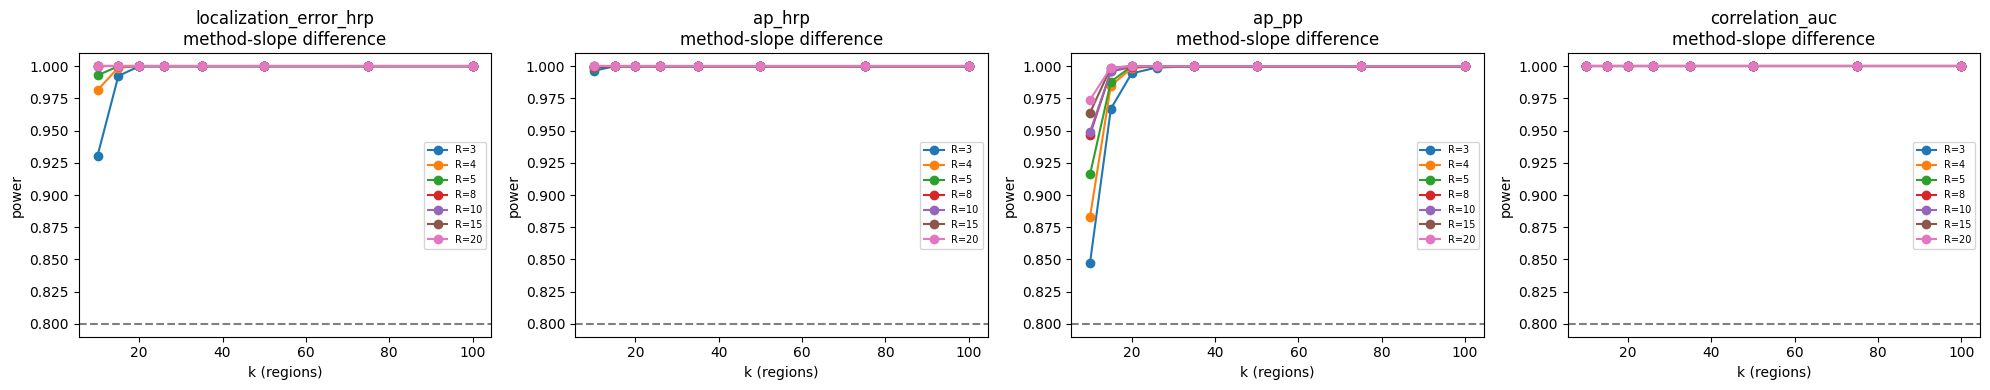

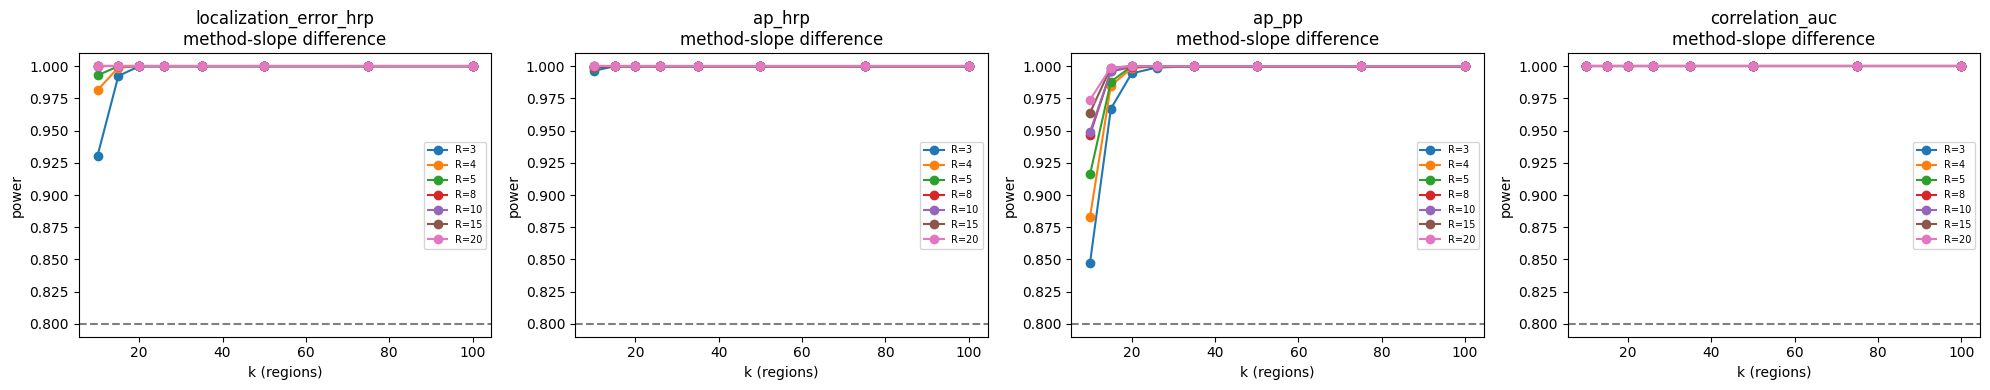

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(5 * len(OUTCOMES), 4))
for ax, outcome in zip(axes, OUTCOMES):
    for j, R in enumerate(r_grid):
        ax.plot(k_grid, power_results[outcome][:, j], marker="o", label=f"R={R}")
    ax.axhline(0.8, ls="--", c="gray")
    ax.set_xlabel("k (regions)"); ax.set_ylabel("power"); ax.set_title(f"{outcome}\nmethod-slope difference")
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("pilot_noise_slope_power_curves.png", dpi=130)
fig

## Recommendation

Sized to the worst outcome across the grid -- same "size to the hardest
case" principle as every other pilot here.

In [6]:
worst = np.ones((len(k_grid), len(r_grid)))
for outcome in OUTCOMES:
    worst = np.minimum(worst, power_results[outcome])

THRESHOLD = 0.8
ok = worst >= THRESHOLD
if ok.any():
    total = np.array(k_grid)[:, None] * np.array(r_grid)[None, :]
    candidates = np.where(ok, total, np.inf)
    i, j = np.unravel_index(np.argmin(candidates), candidates.shape)
    print(f"Smallest design clearing {THRESHOLD} power everywhere: "
          f"k={k_grid[i]} regions, R={r_grid[j]} repetitions/level "
          f"(worst-case power={worst[i, j]:.3f}).")
else:
    i, j = np.unravel_index(np.argmax(worst), worst.shape)
    print(f"No (k, R) in this grid reaches {THRESHOLD} power everywhere -- "
          f"best achieved is {worst.max():.3f} at k={k_grid[i]}, R={r_grid[j]}.")

Smallest design clearing 0.8 power everywhere: k=10 regions, R=3 repetitions/level (worst-case power=0.848).
